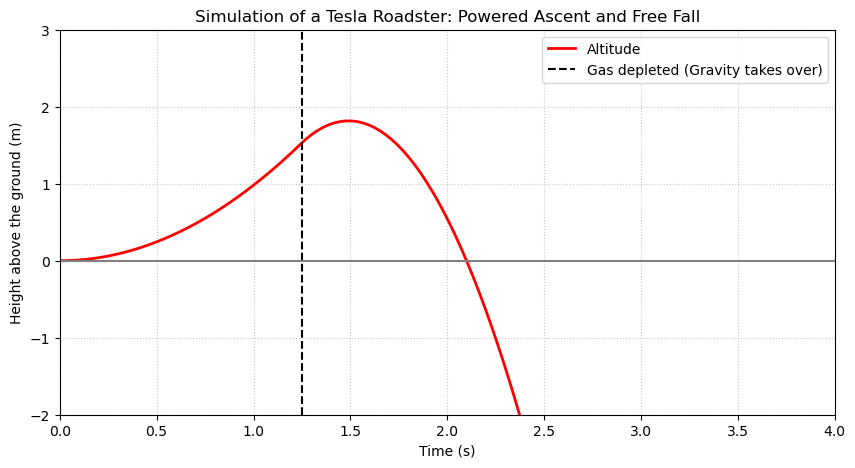

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy import constants

m_car = 2000.0
Cd = 0.30
A = 2.0
rho_air = 1.225
V_tank = 0.1
P_tank = 300e5
T_tank = 293.15
P_atm = constants.atm
gamma = 1.4
M_gas = 0.02897
R = constants.R
R_spec = R / M_gas
g = constants.g

v_exhaust = np.sqrt((2 * gamma / (gamma - 1)) * R_spec * T_tank * (1 - (P_atm / P_tank) ** ((gamma - 1) / gamma)))
m_gas = (P_tank * V_tank) / (R_spec * T_tank)
F_required = m_car * g
m_dot_required = F_required / v_exhaust
t_hover = m_gas / m_dot_required

def flight_dynamics(t, state, t_burn):
    y, v = state
    if t < t_burn:
        thrust = F_required * 1.2
    else:
        thrust = 0.0
    drag = 0.5 * rho_air * Cd * A * v * np.abs(v)
    a = (thrust - m_car * g - drag) / m_car
    return [v, a]

t_span = (0, max(15, t_hover + 5))
t_eval = np.linspace(t_span[0], t_span[1], 500)
initial_state = [0.0, 0.0]
sol = solve_ivp(flight_dynamics, t_span, initial_state, 
                t_eval=t_eval, args=(t_hover,))

plt.figure(figsize=(10, 5))
plt.plot(sol.t, sol.y[0], color='red', linewidth=2, label='Altitude')
plt.axvline(x=t_hover, color='black', linestyle='--', label='Gas depleted (Gravity takes over)')
plt.axhline(y=0, color='gray', linestyle='-')
plt.xlim(0,4)
plt.ylim(-2, 3)
plt.title('Simulation of a Tesla Roadster: Powered Ascent and Free Fall')
plt.xlabel('Time (s)')
plt.ylabel('Height above the ground (m)')
plt.grid(True, linestyle=':', alpha=0.7)

plt.legend()
plt.show()